# Giải thích cho FFT 1000 điểm và 4096 điểm

**Mục tiêu:** Quan sát vì sao nhiều điểm FFT hơn tạo lưới tần số mịn hơn khi tín hiệu thực vẫn chỉ có 1000 mẫu.

- Tần số lấy mẫu: $F_s = 125\ \mathrm{Hz}$.
- Số mẫu thực: $L = 1000$, tương ứng $T = L/F_s = 8\ \mathrm{s}$.
- FFT 1000 điểm dùng trực tiếp tín hiệu; FFT 4096 điểm thêm **3096 số 0** vào cuối (*zero-padding*).
- FFT là thuật toán tính DFT. Khoảng cách giữa hai bin là $\Delta f=F_s/N_{\mathrm{FFT}}$.

Notebook cần **NumPy** và **Matplotlib**. Nếu kernel chưa có thư viện, cài trong đúng môi trường Python của kernel bằng `%pip install numpy matplotlib`. Để dùng môi trường đó làm kernel trong VS Code/Jupyter, cài thêm `ipykernel` nếu cần.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10, "figure.dpi": 120})

fs = 125
n_samples = 1000
n_fft_small = 1000
n_fft_large = 4096
frequency_true = 1.43  # Hz: chọn tần số không trùng bin của FFT 1000 điểm.

t = np.arange(n_samples) / fs
signal = np.sin(2 * np.pi * frequency_true * t)
signal_padded = np.pad(signal, (0, n_fft_large - n_samples))

print(f"Số mẫu đo thực: {len(signal)}; thời gian quan sát: {n_samples / fs:.3f} s")
print(f"FFT 4096: giữ {n_samples} mẫu thực và thêm {len(signal_padded) - n_samples} số 0.")
print(f"Tần số tín hiệu minh họa: {frequency_true:.3f} Hz = {60 * frequency_true:.3f} BPM")

Số mẫu đo thực: 1000; thời gian quan sát: 8.000 s
FFT 4096: giữ 1000 mẫu thực và thêm 3096 số 0.
Tần số tín hiệu minh họa: 1.430 Hz = 85.800 BPM


## 1. Zero-padding giữ nguyên 1000 mẫu thực

Phần màu xám bên dưới chỉ chứa số 0 được thêm bằng máy tính. Độ dài mảng tăng nhưng không có thêm dữ liệu đo.

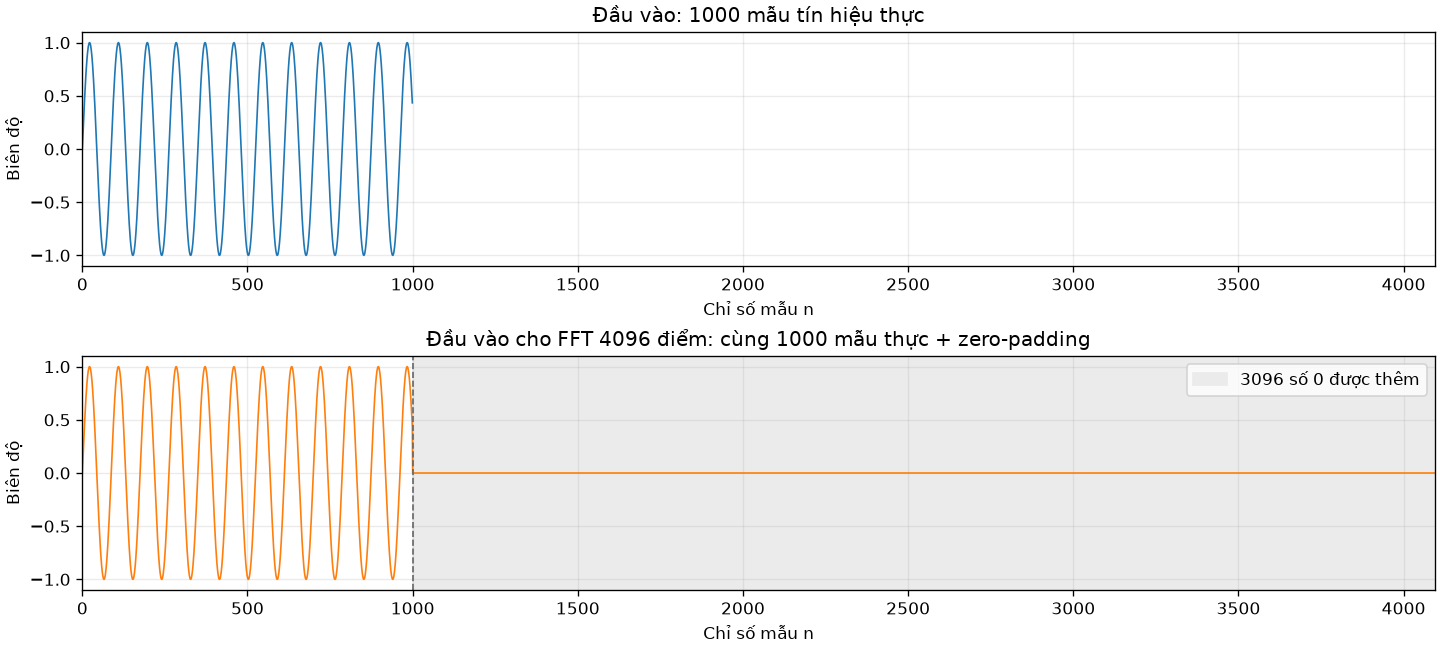

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.4), constrained_layout=True)

axes[0].plot(np.arange(n_samples), signal, color="C0", linewidth=1)
axes[0].set(title="Đầu vào: 1000 mẫu tín hiệu thực", xlim=(0, n_fft_large - 1))

axes[1].axvspan(n_samples, n_fft_large - 1, color="0.92", label="3096 số 0 được thêm")
axes[1].plot(np.arange(n_fft_large), signal_padded, color="C1", linewidth=1)
axes[1].axvline(n_samples, color="0.4", linestyle="--", linewidth=1)
axes[1].set(title="Đầu vào cho FFT 4096 điểm: cùng 1000 mẫu thực + zero-padding",
            xlim=(0, n_fft_large - 1))
axes[1].legend(loc="upper right")

for ax in axes:
    ax.set(xlabel="Chỉ số mẫu n", ylabel="Biên độ")
    ax.grid(alpha=0.25)
plt.show()

## 2. So sánh lưới tần số và vị trí đỉnh phổ

Với tín hiệu được bổ sung số 0, công thức DFT là:

$$
X_N[k]=\sum_{n=0}^{999}x[n]e^{-j2\pi kn/N},
\qquad f_k=\frac{kF_s}{N}.
$$

Tổng vẫn chỉ sử dụng 1000 mẫu thực. Khi thay $N$ từ 1000 thành 4096, ta lấy mẫu **cùng một phổ DTFT** tại nhiều vị trí tần số hơn.

Trong code, biên độ của cả hai phổ được chuẩn hóa theo **số mẫu thực**, không chia cho số điểm FFT. Nhờ vậy, việc thêm số 0 không làm giảm biên độ hiển thị.

In [3]:
def amplitude_spectrum(samples, n_fft, fs):
    """Phổ biên độ một phía; zero-padding không thay đổi hệ số chuẩn hóa."""
    samples = np.asarray(samples)
    if n_fft < len(samples):
        raise ValueError("n_fft phải >= số mẫu thực để tránh cắt tín hiệu.")
    frequency = np.fft.rfftfreq(n_fft, d=1 / fs)
    amplitude = np.abs(np.fft.rfft(samples, n=n_fft)) / len(samples)
    # Gộp năng lượng biên độ của hai phía; DC và Nyquist không nhân đôi.
    if n_fft % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2
    return frequency, amplitude


f_1000, a_1000 = amplitude_spectrum(signal, n_fft_small, fs)
f_4096, a_4096 = amplitude_spectrum(signal, n_fft_large, fs)

print(f"{'N FFT':>7} {'Mẫu thực':>10} {'Δf (Hz)':>12} {'60Δf (BPM)':>14} {'Đỉnh (Hz)':>12}")
for n_fft, frequency, amplitude in [(n_fft_small, f_1000, a_1000),
                                    (n_fft_large, f_4096, a_4096)]:
    peak = np.argmax(amplitude)
    print(f"{n_fft:7d} {len(signal):10d} {fs / n_fft:12.6f}"
          f" {60 * fs / n_fft:14.6f} {frequency[peak]:12.6f}")

print(f"\nLưới FFT 4096 dày hơn {n_fft_large / n_fft_small:.3f} lần.")

  N FFT   Mẫu thực      Δf (Hz)     60Δf (BPM)    Đỉnh (Hz)
   1000       1000     0.125000       7.500000     1.375000
   4096       1000     0.030518       1.831055     1.434326

Lưới FFT 4096 dày hơn 4.096 lần.


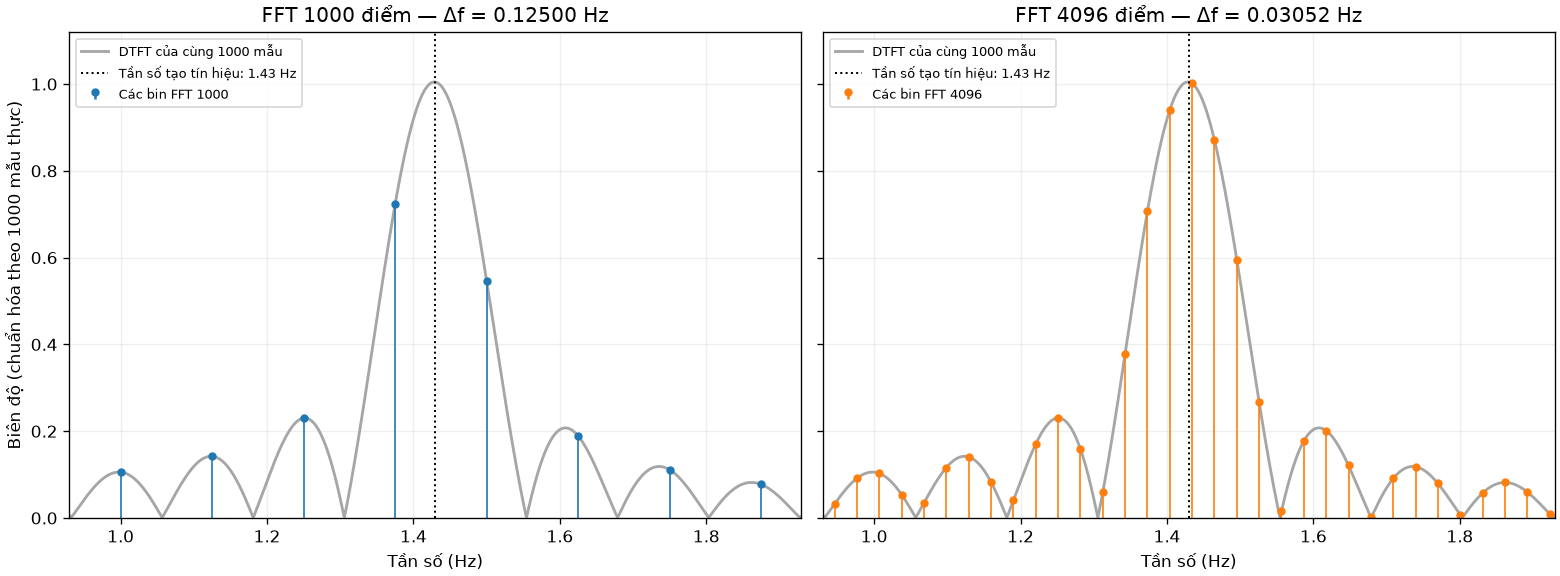

In [4]:
# Tính trực tiếp DTFT trong vùng cần xem để vẽ đường phổ tham chiếu.
# Đường này cũng chỉ dùng 1000 mẫu thực, không thêm thông tin đo.
f_dense = np.linspace(frequency_true - 0.5, frequency_true + 0.5, 2000)
a_dense = 2 * np.abs(np.exp(-2j * np.pi * f_dense[:, None] * t[None, :]) @ signal) / len(signal)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True,
                         constrained_layout=True)
settings = [(n_fft_small, f_1000, a_1000, "C0"),
            (n_fft_large, f_4096, a_4096, "C1")]
for ax, (n_fft, frequency, amplitude, color) in zip(axes, settings):
    ax.plot(f_dense, a_dense, color="0.65", linewidth=1.7,
            label="DTFT của cùng 1000 mẫu")
    visible = (frequency >= f_dense[0]) & (frequency <= f_dense[-1])
    markerline, stemlines, baseline = ax.stem(
        frequency[visible], amplitude[visible], linefmt=color + "-",
        markerfmt=color + "o", basefmt=" ", label=f"Các bin FFT {n_fft}")
    plt.setp(markerline, markersize=4)
    plt.setp(stemlines, linewidth=1)
    ax.axvline(frequency_true, color="black", linestyle=":", linewidth=1.2,
               label=f"Tần số tạo tín hiệu: {frequency_true:.2f} Hz")
    ax.set(title=f"FFT {n_fft} điểm — Δf = {fs / n_fft:.5f} Hz",
           xlabel="Tần số (Hz)", xlim=(f_dense[0], f_dense[-1]), ylim=(0, 1.12))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Biên độ (chuẩn hóa theo 1000 mẫu thực)")
plt.show()

**Quan sát:** Các điểm FFT 4096 nằm dày hơn trên cùng đường phổ xám. Trong ví dụ này, bin đỉnh của FFT 4096 cũng gần tần số tạo tín hiệu hơn. Đây là lợi ích khi chọn đỉnh trên lưới; không phải cam kết sai số luôn giảm với mọi tín hiệu và mức nhiễu.

$$
\Delta f_{1000}=0{,}125\ \mathrm{Hz},
\qquad
\Delta f_{4096}\approx0{,}03052\ \mathrm{Hz}.
$$

Khi đổi sang nhịp tim, khoảng cách giữa hai bin tương ứng là **7,5 BPM** và **1,831 BPM**. Đây là bước lưới của BPM thô từ bin FFT, không phải độ chính xác đo nhịp tim.

## 3. Lưới mịn hơn và thu thêm mẫu thực là hai việc khác nhau

Tạo một tín hiệu có hai thành phần gần nhau: **1,40 Hz** và **1,47 Hz**. So sánh:

1. **1000 mẫu thực + 3096 số 0:** quan sát 8 giây, FFT 4096 điểm.
2. **4096 mẫu thực:** quan sát 32,768 giây, cũng FFT 4096 điểm.

Hai trường hợp có cùng $\Delta f=125/4096$ Hz, nhưng thời gian đo khác nhau. Với cửa sổ chữ nhật đang dùng, thang tần số đặc trưng liên quan đến bề rộng búp chính là $1/T$; khả năng tách hai thành phần còn phụ thuộc dạng cửa sổ, biên độ, pha và nhiễu.

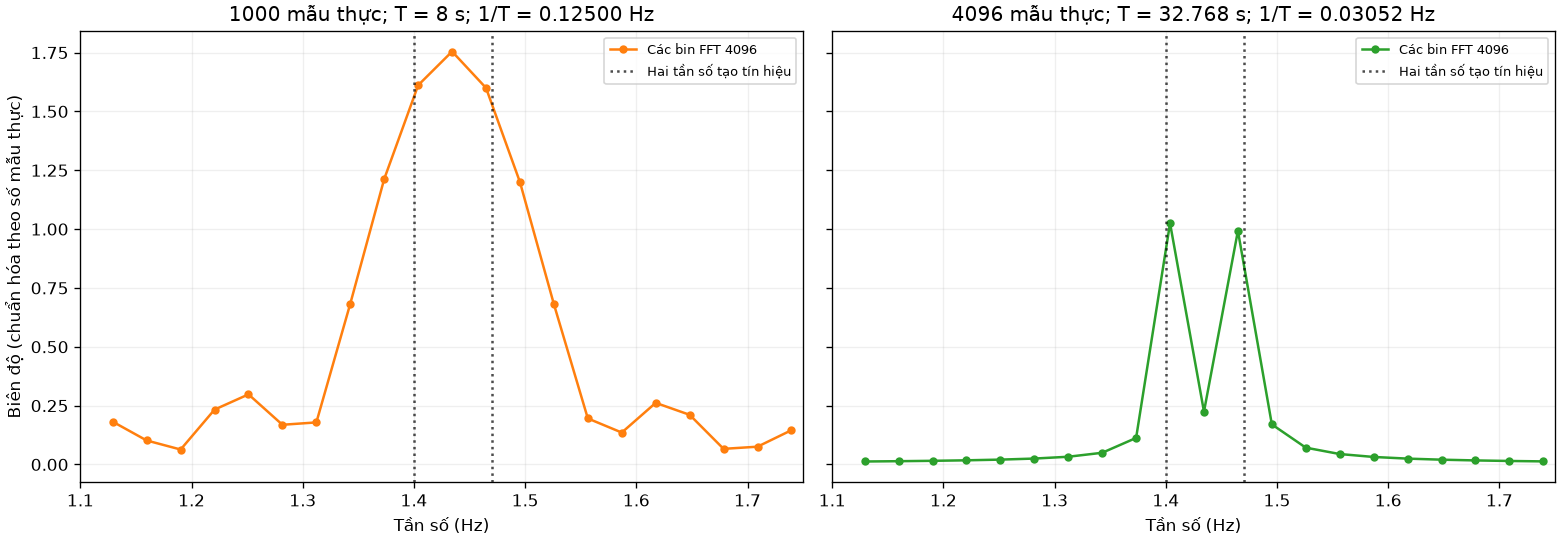

Khoảng cách hai tần số thật: 0.070 Hz
Đo 8 giây: 1/T = 0.12500 Hz
Đo 32.768 giây: 1/T = 0.03052 Hz


In [5]:
close_frequencies = (1.40, 1.47)
phase_origin = t.mean()


def two_close_tones(time):
    # Cùng một tín hiệu liên tục cho cả đoạn ngắn và đoạn dài.
    return sum(np.cos(2 * np.pi * f * (time - phase_origin)) for f in close_frequencies)


t_long = np.arange(n_fft_large) / fs
short_signal = two_close_tones(t)
long_signal = two_close_tones(t_long)

f_short, a_short = amplitude_spectrum(short_signal, n_fft_large, fs)
f_long, a_long = amplitude_spectrum(long_signal, n_fft_large, fs)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, frequency, amplitude, n_real, color in [
    (axes[0], f_short, a_short, n_samples, "C1"),
    (axes[1], f_long, a_long, n_fft_large, "C2"),
]:
    visible = (frequency >= 1.1) & (frequency <= 1.75)
    ax.plot(frequency[visible], amplitude[visible], "o-", color=color,
            markersize=4, label="Các bin FFT 4096")
    for i, f in enumerate(close_frequencies):
        ax.axvline(f, color="black", linestyle=":", alpha=0.7,
                   label="Hai tần số tạo tín hiệu" if i == 0 else None)
    duration = n_real / fs
    ax.set(title=f"{n_real} mẫu thực; T = {duration:g} s; 1/T = {1 / duration:.5f} Hz",
           xlabel="Tần số (Hz)", xlim=(1.1, 1.75))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Biên độ (chuẩn hóa theo số mẫu thực)")
plt.show()

print(f"Khoảng cách hai tần số thật: {close_frequencies[1] - close_frequencies[0]:.3f} Hz")
print(f"Đo 8 giây: 1/T = {fs / n_samples:.5f} Hz")
print(f"Đo 32.768 giây: 1/T = {fs / n_fft_large:.5f} Hz")

## Kết luận để trình bày

> **Nhiều điểm FFT hơn làm lưới tần số mịn hơn. Khi chỉ thêm số 0, ta lấy mẫu phổ dày hơn từ cùng đoạn tín hiệu. Muốn tăng thông tin quan sát và cải thiện khả năng phân biệt các tần số gần nhau, cần thu thêm mẫu thực hoặc thay đổi cách quan sát phù hợp.**

Trong đồ án CPC, mỗi cửa sổ vẫn chỉ có **1000 mẫu / 8 giây**. FFT 4096 điểm dùng zero-padding để thuận tiện chọn đỉnh phổ và đổi bin sang BPM.